# Final Project 1 — Screw Head Segmentation from Scratch

## Score (out of 100) = 100 × test mIoU − 5 × log10(parameters in millions, at least 1)

### A pretrained weight in `model`, opening the test images or labels yourself, or labels downloaded from the original datasets, is cheating → mIoU points = 0

Find every screw and name its **head type** — button, flat or pan — with a model trained from random weights.

**Input** a photograph → **Output** a class for every pixel

Only **50 of the 500 training images are labelled**: label more yourself.

### Terms

- **Score** → out of 100, never below 0
- **mIoU** → IoU of each head type over the test pixels, averaged
- **Size** → parameters of `model`; 1 M or fewer → 0, 10 M → −5, 100 M → −10
- **Time** → per image; printed, not scored
- **Original datasets** → Roboflow Universe "Screw classification" (project-s0l2s) and MVTec Screws; they publish these photographs with labels
- **From scratch** → every weight of `model` starts random

### Tips

- **Tip 1.** Train on the 50 labelled images first, and look at what that model gets wrong
- **Tip 2.** Look for an efficient way to label the 450 unlabelled images
- **Tip 3.** Judge every choice on validation images of your own, never on the test images
- **Tip 4.** Parameters cost points; a larger model has to earn them back in mIoU

### Setup and Data

- Data → Roboflow Universe "Screw classification" by project-s0l2s (CC BY 4.0), with photographs of MVTec Screws (CC BY-NC-SA 4.0)
- Training needs a GPU: on Colab the free T4 is enough, and a paid plan offers faster GPUs; make a short run first

In [1]:
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Polygon
from PIL import Image, ImageDraw

np.random.seed(42)
torch.manual_seed(42)

# weights and other files you make go under build/, the dataset under data/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


In [2]:
screw_dir = DATA / 'screw_seg'

if not screw_dir.exists():
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jongmoonha/Ajou_ME_AI_Undergraduate/main/data/screw_seg_train.zip', BUILD / 'screw_seg_train.zip')
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jongmoonha/Ajou_ME_AI_Undergraduate/main/data/screw_seg_test.zip', BUILD / 'screw_seg_test.zip')
    # the two archives have no top level folder inside, so the destination folder is named here
    with zipfile.ZipFile(BUILD / 'screw_seg_train.zip') as archive:
        archive.extractall(screw_dir)
    with zipfile.ZipFile(BUILD / 'screw_seg_test.zip') as archive:
        archive.extractall(screw_dir)

labelled_images = sorted((screw_dir / 'labelled' / 'images').glob('*.jpg'))
unlabelled_images = sorted((screw_dir / 'unlabelled' / 'images').glob('*.jpg'))
test_images = sorted((screw_dir / 'test' / 'images').glob('*.jpg'))

print(f'labelled   : {len(labelled_images)} images')
print(f'unlabelled : {len(unlabelled_images)} images')
print(f'test       : {len(test_images)} images')

labelled   : 50 images
unlabelled : 450 images
test       : 100 images


### Labelled, Unlabelled and Test (given)

- `labelled` → 50 training images with labels, `unlabelled` → 450 training images without labels, `test` → for the evaluation cells
- One label file per image, one line per screw: `class x1 y1 x2 y2 ...`, the corners of a polygon as fractions of the image width and height
- `load_class_map` turns a label file into the class map that the evaluation cells score; keep it and `test_images` as they are

In [3]:
def load_class_map(label_path, size):
    # label file → class map for an image of that (width, height): the class index of the file + 1 on each screw, 0 elsewhere
    class_map = Image.new('L', size, 0)
    draw = ImageDraw.Draw(class_map)
    for line in label_path.read_text().strip().splitlines():
        values = line.split()
        corners = np.array([float(value) for value in values[1:]]).reshape(-1, 2)
        corners[:, 0] = corners[:, 0] * size[0]
        corners[:, 1] = corners[:, 1] * size[1]
        draw.polygon([tuple(corner) for corner in corners], fill=int(values[0]) + 1)
    return np.array(class_map)


image = Image.open(labelled_images[0])
class_map = load_class_map(screw_dir / 'labelled' / 'labels' / (labelled_images[0].stem + '.txt'), image.size)

print(f'image     : size {image.size}, mode {image.mode}')
print(f'class map : shape {class_map.shape}, values {np.unique(class_map)}')

image     : size (800, 600), mode RGB
class map : shape (600, 800), values [0 2]


### Data Exploration

| Value in the class map | Class | Index in the label files | Looks like |
|:---|:---|:---|:---|
| 0 | `background` | — | everything else |
| 1 | `button_head` | 0 | a small rounded dome |
| 2 | `flat_head` | 1 | a flat top over a cone |
| 3 | `pan_head` | 2 | a wide head that stands above the surface |

- The 50 labelled images hold 14 button, 236 flat and 68 pan head screws
- Nuts and washers are not labelled: they are background

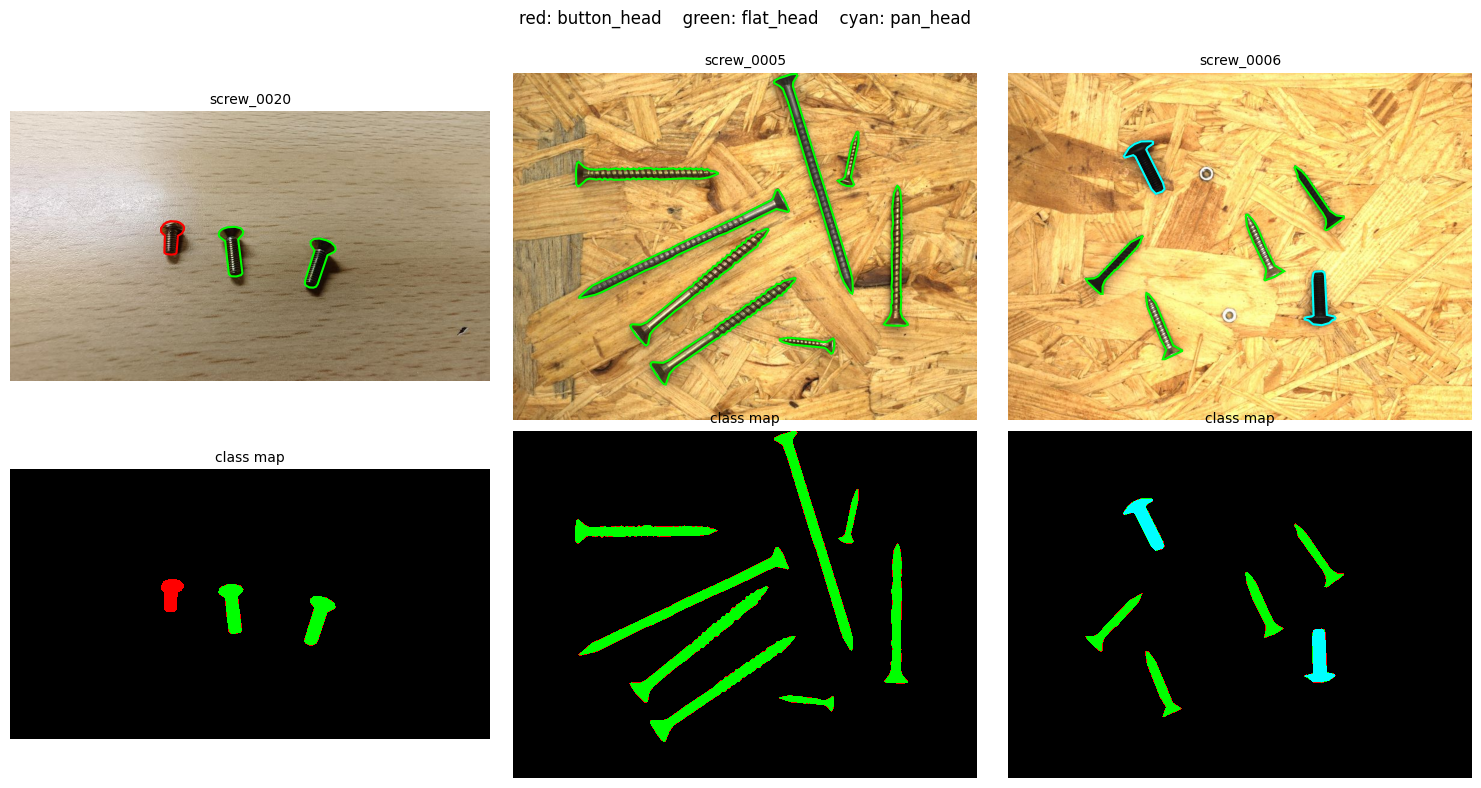

In [4]:
# one labelled image per head type: the photograph with its polygons (top) and its class map (bottom)
class_colors = ['black', 'red', 'lime', 'cyan']
class_cmap = ListedColormap(class_colors)
label_paths = sorted((screw_dir / 'labelled' / 'labels').glob('*.txt'))

shown_paths = []
for class_index in range(3):
    for label_path in label_paths:
        classes_here = [int(line.split()[0]) for line in label_path.read_text().strip().splitlines()]
        if class_index in classes_here and label_path not in shown_paths:
            shown_paths.append(label_path)
            break

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, label_path in enumerate(shown_paths):
    image = Image.open(screw_dir / 'labelled' / 'images' / (label_path.stem + '.jpg'))
    width, height = image.size

    axes[0, column].imshow(image)
    for line in label_path.read_text().strip().splitlines():
        values = line.split()
        corners = np.array([float(value) for value in values[1:]]).reshape(-1, 2)
        corners[:, 0] = corners[:, 0] * width
        corners[:, 1] = corners[:, 1] * height
        axes[0, column].add_patch(Polygon(corners, fill=False, edgecolor=class_colors[int(values[0]) + 1], linewidth=1.5))
    axes[0, column].set_title(label_path.stem, fontsize=10)
    axes[0, column].axis('off')

    axes[1, column].imshow(load_class_map(label_path, image.size), cmap=class_cmap, vmin=0, vmax=3)
    axes[1, column].set_title('class map', fontsize=10)
    axes[1, column].axis('off')

fig.suptitle('red: button_head    green: flat_head    cyan: pan_head', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97))      # leaves room for the title above the panels
plt.show()

---
## Work Area

### What to Follow

#### 1. Labels

Label any of the 450 unlabelled images, with any tool (model-assisted included), in the format above.

#### 2. Original Datasets

The files given in this notebook are yours to use; **labels downloaded from the two original datasets → mIoU points 0.**

#### 3. Other Data

Any other dataset is allowed; list each one in `data_sources`.

#### 4. Model

One `torch.nn.Module`, every weight from random initialization: your own layers or a library architecture.

#### 5. Test Images

**Leave them to the evaluation cells** — opening the test images or labels yourself → mIoU points 0.

### What to Define at the End

The evaluation cells need three names:

- `model` — the `torch.nn.Module` you predict with; all its parameters are counted
  - an Ultralytics `YOLO` object → its `.model`
- `predict` — `predict(image)` returns the class map of one image
  - `image` → PIL image from disk
  - class map → NumPy integer array, shape (image height, image width), values 0–3 as in the table
- `data_sources` — list of strings, name and address of each dataset you added; `[]` if none

In [ ]:
# Write your code from here; add cells with [+] as needed.

---
## Evaluation (do not modify)

Run the three cells below as they are; Evaluation 3 prints your score.

- **Evaluation 1** → `predict` on the 100 test images, time per image
- **Evaluation 2** → IoU of each head type over all test pixels, $A$ = yours, $B$ = the true ones; mIoU = their mean
- **Evaluation 3** → parameters of `model`, four of your class maps, your data sources, your score out of 100

$$\text{IoU} = \frac{|A \cap B|}{|A \cup B|}$$

In [ ]:
# === Evaluation 1: predictions and time per image ===
# Your `predict` must be defined.
import time

pred_maps = {}

time_start = time.perf_counter()
for image_path in test_images:
    image = Image.open(image_path)
    class_map_pred = np.array(predict(image))
    image_shape = (image.height, image.width)
    if class_map_pred.shape != image_shape:
        raise ValueError(f'class map of {image_path.name} has shape {class_map_pred.shape}, expected {image_shape}')
    if class_map_pred.dtype.kind not in 'iu' or class_map_pred.min() < 0 or class_map_pred.max() > 3:
        raise ValueError(f'class map of {image_path.name} must hold the integers 0, 1, 2, 3')
    pred_maps[image_path.stem] = class_map_pred
time_end = time.perf_counter()
time_per_image = 1000 * (time_end - time_start) / len(test_images)      # milliseconds, reading the file included

print(f'test images    : {len(test_images)}')
print(f'time per image : {time_per_image:.1f} ms')

In [ ]:
# === Evaluation 2: IoU of each head type and mIoU ===
# `pred_maps` from Evaluation 1 must be defined.
intersections = np.zeros(4)
unions = np.zeros(4)

for image_path in test_images:
    image = Image.open(image_path)
    class_map_true = load_class_map(screw_dir / 'test' / 'labels' / (image_path.stem + '.txt'), image.size)
    class_map_pred = pred_maps[image_path.stem]
    for class_value in [1, 2, 3]:
        pixels_pred = class_map_pred == class_value
        pixels_true = class_map_true == class_value
        intersections[class_value] += np.logical_and(pixels_pred, pixels_true).sum()
        unions[class_value] += np.logical_or(pixels_pred, pixels_true).sum()

iou_button = intersections[1] / unions[1]
iou_flat = intersections[2] / unions[2]
iou_pan = intersections[3] / unions[3]
miou_test = (iou_button + iou_flat + iou_pan) / 3

print(f'button_head IoU = {iou_button:.4f}')
print(f'flat_head   IoU = {iou_flat:.4f}')
print(f'pan_head    IoU = {iou_pan:.4f}')
print()
print(f'test mIoU       : {miou_test:.4f}')

In [ ]:
# === Evaluation 3: model size, pictures, data sources and score ===
# Your `model` and `data_sources` must be defined, and Evaluations 1 and 2 must have run.
n_parameters = sum(p.numel() for p in model.parameters())
n_millions = n_parameters / 1e6

fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for column, image_path in enumerate(test_images[:4]):
    image = Image.open(image_path)
    class_map_true = load_class_map(screw_dir / 'test' / 'labels' / (image_path.stem + '.txt'), image.size)
    axes[0, column].imshow(image)
    axes[0, column].set_title(image_path.stem, fontsize=10)
    axes[1, column].imshow(class_map_true, cmap=class_cmap, vmin=0, vmax=3)
    axes[1, column].set_title('true class map', fontsize=10)
    axes[2, column].imshow(pred_maps[image_path.stem], cmap=class_cmap, vmin=0, vmax=3)
    axes[2, column].set_title('your class map', fontsize=10)
    for row in range(3):
        axes[row, column].axis('off')

fig.suptitle('red: button_head    green: flat_head    cyan: pan_head', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97))      # leaves room for the title above the panels
plt.show()

print(f'data sources : {len(data_sources)}')
for source in data_sources:
    print(f'  - {source}')

miou_points = 100 * miou_test
size_points = 5 * np.log10(max(1.0, n_millions))       # points off: 1 M or fewer → 0, 10 M → 5, 100 M → 10
score = max(0.0, miou_points - size_points)            # never below 0

print('=' * 72)
print(f'  test mIoU      : {miou_test:.4f}')
print(f'  parameters     : {n_millions:.2f} M')
print(f'  time per image : {time_per_image:.1f} ms   (not scored)')
print(f'  score          : {score:.1f} / 100   (mIoU {miou_points:.1f} - size {size_points:.1f})')
print('=' * 72)

---
## Presentation (weeks 15 and 16)

- Per student, both notebooks in 9 minutes: 6 presentation + 3 Q&A
- 2 × 100 = 200 points; presentation graded separately

1. **Data** → what you labelled or added, and why
2. **Approach** → model and training in each notebook, why
3. **Validation** → what you compared, what moved the score
4. **Test result** → mIoU or mAP, parameters, time
5. **Scratch against fine-tuning** → what differed, and why
6. **Failure cases** → what the predictions get wrong

---
## Before You Submit

- **Individual project** → every student submits their own work
- Run the notebook top to bottom and keep every output
- An error in an evaluation cell → no score for this project
- **Opening the test images or labels yourself, or labels downloaded from the two original datasets → mIoU points 0**
- **A pretrained weight in `model`, or a trained weight that `predict` uses outside `model` → mIoU points 0**

### What to Submit

| Submit | File name |
|:---|:---|
| this notebook | `Final_Project_1_Name_StudentID.ipynb` |
| its PDF | `Final_Project_1_Name_StudentID.pdf` |
| your label files and added data | `Final_Project_Dataset_Name_StudentID.zip` |
| presentation slides, one file for both projects | `Final_Project_Presentation_Name_StudentID.pptx` |